In [1]:
#1.LOAD DATA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

df = pd.read_excel("shopping_behavior_updated (1).xlsx")

print(df.head())
print(df.info())
print(df.shape)

   Customer ID  Age Gender Item Purchased  Category  Purchase Amount (USD)  \
0            1   55   Male         Blouse  Clothing                     53   
1            2   19   Male        Sweater  Clothing                     64   
2            3   50   Male          Jeans  Clothing                     73   
3            4   21   Male        Sandals  Footwear                     90   
4            5   45   Male         Blouse  Clothing                     49   

        Location Size      Color  Season  Review Rating Subscription Status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

  Discount Applied  Previous Purchases Payment Method Fr

In [2]:
#2.CHECK MISSING VALUE
print(df.isnull().sum())

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Discount Applied          0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64


In [3]:
#3. ENCODE CATEGORICALS

df_cleaned = df.drop(columns=['Customer ID', 'Location', 'Frequency of Purchases'])

In [4]:
categorical_cols = df_cleaned.select_dtypes(include=['object']).columns

In [5]:
df_numeric = df_cleaned.copy()
encoder = OrdinalEncoder()
df_numeric[categorical_cols] = encoder.fit_transform(df_cleaned[categorical_cols].astype(str))

In [6]:
print(df_numeric.columns)
print(df_numeric.shape)

Index(['Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)',
       'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status',
       'Discount Applied', 'Previous Purchases', 'Payment Method'],
      dtype='object')
(3900, 13)



--- Descriptive Statistics Summary ---
           Age   Gender  Item Purchased  Category  Purchase Amount (USD)  \
count  3900.00  3900.00         3900.00    3900.0                3900.00   
mean     44.07     0.68           12.04       1.0                  59.76   
std      15.21     0.47            7.20       0.9                  23.69   
min      18.00     0.00            0.00       0.0                  20.00   
25%      31.00     0.00            6.00       0.0                  39.00   
50%      44.00     1.00           12.00       1.0                  60.00   
75%      57.00     1.00           18.00       1.0                  81.00   
max      70.00     1.00           24.00       3.0                 100.00   

          Size    Color   Season  Review Rating  Subscription Status  \
count  3900.00  3900.00  3900.00        3900.00              3900.00   
mean      1.12    12.11     1.49           3.75                 0.27   
std       0.93     7.22     1.12           0.72            

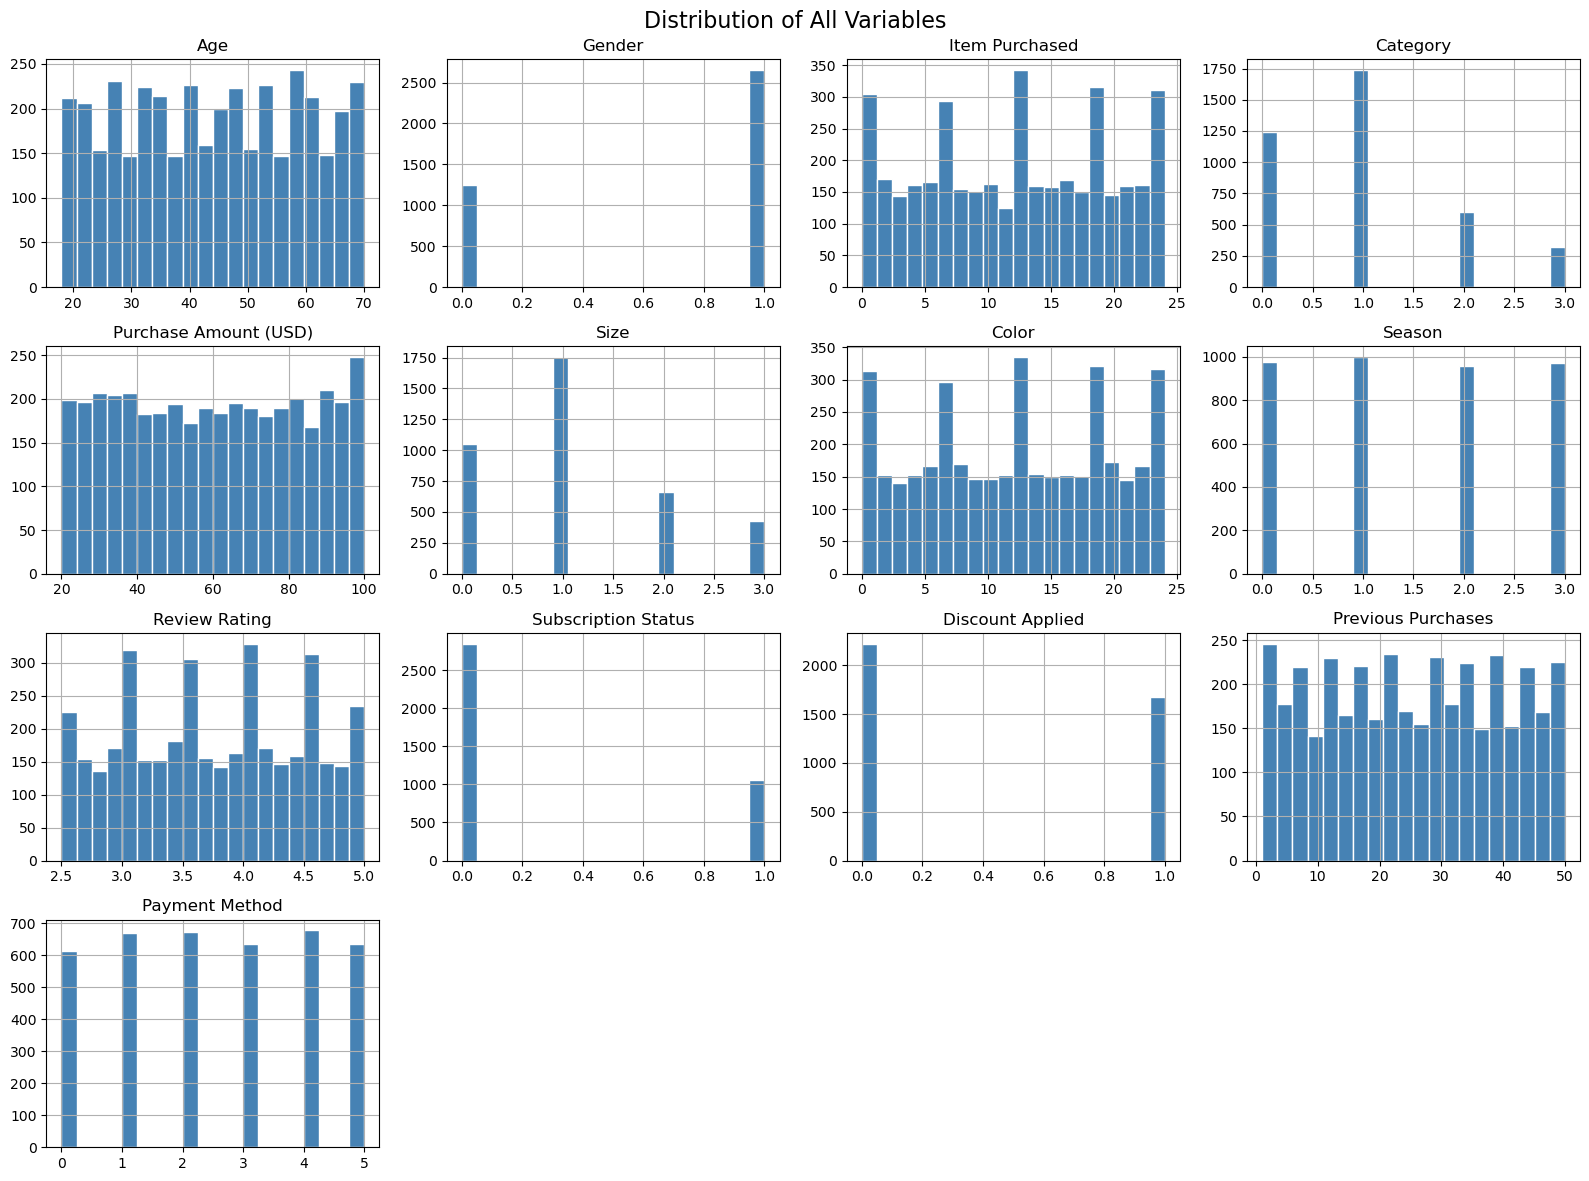

In [7]:
#4. DESCRIPTIVE STATISTIC

print("\n--- Descriptive Statistics Summary ---")
print(df_numeric.describe().round(2))

# Plot historical feature distributions
df_numeric.hist(figsize=(16, 12), bins=20, color='steelblue', edgecolor='white')
plt.suptitle("Distribution of All Variables", fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
#5. STANDARDIZATION(SCALING)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_numeric)

print("\nScaled Data Shape:", X_scaled.shape)


Scaled Data Shape: (3900, 13)


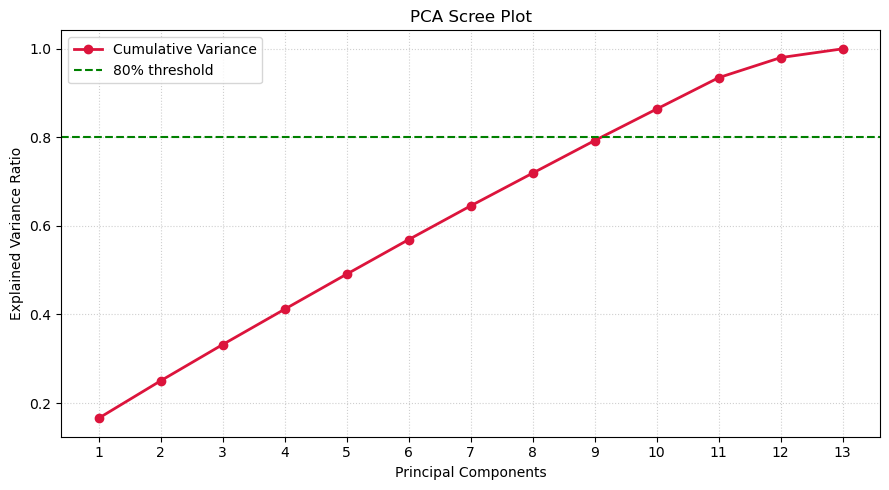

PC1: 0.1657 (16.57%)
PC2: 0.0846 (8.46%)
PC3: 0.0818 (8.18%)
PC4: 0.0799 (7.99%)
PC5: 0.0792 (7.92%)
PC6: 0.0781 (7.81%)
PC7: 0.0762 (7.62%)
PC8: 0.0739 (7.39%)
PC9: 0.0736 (7.36%)
PC10: 0.0712 (7.12%)
PC11: 0.0708 (7.08%)
PC12: 0.0453 (4.53%)
PC13: 0.0198 (1.98%)


In [9]:
#6. SCREE PLOT

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Fit PCA
pca = PCA()
pca.fit(X_scaled)

# Calculate individual and cumulative variance metrics
individual_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(individual_variance)

# Scree plot
plt.figure(figsize=(9, 5))
components = range(1, len(individual_variance) + 1)
plt.plot(components, cumulative_variance, marker='o', color='crimson', linewidth=2, label='Cumulative Variance')
plt.axhline(y=0.80, color='green', linestyle='--', label='80% threshold')

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Scree Plot')
plt.xticks(components)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Print variance per component
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {v:.4f} ({v*100:.2f}%)")

In [10]:
#7. APPLY FINAL PCA & LOADINGS TABLE

import pandas as pd

# Apply PCA with 9 components
pca9 = PCA(n_components=9)
X_pca = pca9.fit_transform(X_scaled)

# Loadings table
loadings = pd.DataFrame(
    pca9.components_.T,
    index=df_numeric.columns,
    columns=[f'PC{i+1}' for i in range(9)]
)
print(loadings.round(3))


                         PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8  \
Age                    0.008 -0.251 -0.411  0.213 -0.531 -0.212  0.038  0.161   
Gender                 0.530  0.042  0.015 -0.016  0.010 -0.024 -0.024  0.039   
Item Purchased        -0.004 -0.370  0.459  0.131 -0.087 -0.186 -0.321  0.220   
Category               0.004 -0.473  0.371 -0.005 -0.097  0.170 -0.330  0.117   
Purchase Amount (USD) -0.020  0.395  0.086  0.295 -0.203  0.043 -0.560 -0.571   
Size                  -0.002  0.534  0.201 -0.069 -0.118 -0.250 -0.028  0.593   
Color                  0.021 -0.117  0.349  0.406 -0.202 -0.109  0.647 -0.295   
Season                 0.014 -0.101  0.099  0.036  0.675 -0.508 -0.007 -0.154   
Review Rating         -0.006  0.294  0.304  0.532  0.104  0.209  0.095  0.243   
Subscription Status    0.572 -0.012  0.014 -0.007 -0.031  0.037 -0.009 -0.035   
Discount Applied       0.623  0.011  0.009 -0.030 -0.006  0.016  0.005 -0.020   
Previous Purchases     0.045

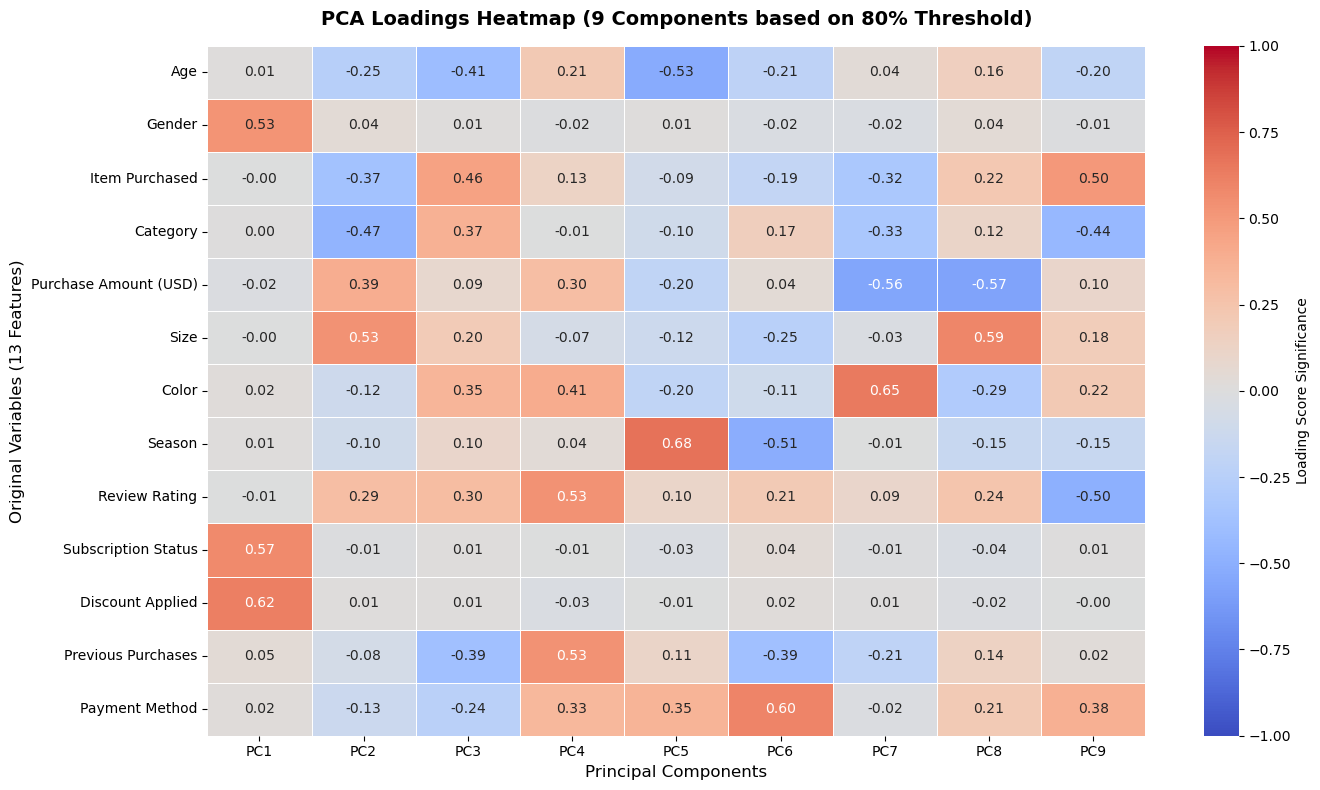

In [11]:
#8. HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt

# Kita besarkan sikit saiz figsize (14, 8) supaya muat untuk 9 lajur PC
plt.figure(figsize=(14, 8))

# Lukis heatmap menggunakan data 'loadings' (9 komponen) yang kita buat di Step 7
sns.heatmap(
    loadings, 
    annot=True,          # Paparkan nombor dalam kotak
    cmap='coolwarm',     # Warna merah (positif kuat), biru (negatif kuat)
    fmt='.2f',           # Setkan kepada 2 titik perpuluhan
    vmin=-1,             # Nilai paling minimum
    vmax=1,              # Nilai paling maksimum
    linewidths=0.5,      # Letak garisan halus antara petak supaya kemas
    cbar_kws={'label': 'Loading Score Significance'} # Label pada palet warna
)

plt.title('PCA Loadings Heatmap (9 Components based on 80% Threshold)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Original Variables (13 Features)', fontsize=12)
plt.xlabel('Principal Components', fontsize=12)

plt.tight_layout()
plt.show()